# Part 3: Multiple comparisons correction
**Lab:** In God we trust, everyone else bring the data · **Analyst:** Ayhan Demir · **Notebook 3 of 5**

**Question for the CMO:** we ran 30 tests. How many of the "wins" could just be luck?
**Reads:** the 3 result tables from notebook 02 · **Writes:** the same 3 tables plus the correction columns, and `correction_comparison.png`


### Setup 
- Loads the libraries used in this lab: pandas/numpy for tables, matplotlib/seaborn for charts, `scipy.stats` for the tests.
- `rng` is the fixed random "dice" (seed 42), so simulations and bootstraps give the same numbers every run.
- `OUT` is the `outputs/` folder where every chart, CSV and the memo are saved. `ALPHA = 0.05` is the significance line.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Load the results from notebook 02

In [2]:
cpa_res = pd.read_csv(OUT / "results_cpa_ttest.csv")
cvr_t_res = pd.read_csv(OUT / "results_conv_rate_ttest.csv")
fisher_res = pd.read_csv(OUT / "results_conv_rate_fisher.csv")
print(len(cpa_res), len(cvr_t_res), len(fisher_res), "comparisons loaded")

10 10 10 comparisons loaded


## Step 6: Bonferroni and Benjamini-Hochberg

**What & why**
- **The problem (§8):** at α = 0.05 every test gives luck a 5% chance. With 30 tests we *expect* about 1.5 false "wins" even if no channel were really different.
- **Bonferroni:** one strict line per family, `α / number of tests` = 0.05 / 10 = **0.005**. It keeps the chance of *even one* fake winner at about 5% (FWER).
- **Benjamini-Hochberg (BH):** `false_discovery_control(..., method="bh")` returns **adjusted p-values**. Significant if adjusted < 0.05. It keeps the *share* of fake winners at about 5% (FDR), so it is less strict.
- The correction is applied **per family** (10 tests each), as the PDF asks ("for each set of comparisons").

In [3]:
families = {"CPA (t-test)": cpa_res, "Conv. rate (t-test)": cvr_t_res, "Conv. rate (Fisher)": fisher_res}

# Total number of tests and expected false positives (tests x 0.05)
total_tests = sum(len(res) for res in families.values())
print(f"Total tests: {total_tests} -> expected false positives at alpha = {ALPHA}: {total_tests * ALPHA:.1f}")
print("Even if no channel were really different, about this many 'significant' results would appear by luck alone.\n")

rows = []
for name, res in families.items():
    m = len(res)
    res["significant_bonferroni"] = res.p_value < ALPHA / m                       # strict line: 0.05 / 10
    res["p_value_fdr"] = false_discovery_control(res.p_value, method="bh")      # BH-adjusted p-values
    res["significant_fdr"] = res.p_value_fdr < ALPHA
    rows.append({"family": name, "tests": m, "uncorrected": res.significant.sum(),
                 "Bonferroni": res.significant_bonferroni.sum(), "BH-FDR": res.significant_fdr.sum()})
correction_summary = pd.DataFrame(rows).set_index("family")
correction_summary

Total tests: 30 -> expected false positives at alpha = 0.05: 1.5
Even if no channel were really different, about this many 'significant' results would appear by luck alone.



,tests,uncorrected,Bonferroni,BH-FDR
family,,,,
CPA (t-test),10,7,5,7
Conv. rate (t-test),10,6,5,6
Conv. rate (Fisher),10,10,10,10


**Which comparisons lose significance, plus the chart**
- For each family, the cell lists the pairs that were significant before correction but not after Bonferroni, or not after BH.
- The grouped bar chart shows the three counts side by side for each family.


=== CPA (t-test) ===
  Lost after Bonferroni: ['def vs ghi', 'def vs jkl']
  Lost after BH:         none
  Still significant after BH: ['abc vs def', 'abc vs ghi', 'abc vs jkl', 'abc vs mno', 'def vs ghi', 'def vs jkl', 'def vs mno']

=== Conv. rate (t-test) ===
  Lost after Bonferroni: ['ghi vs mno']
  Lost after BH:         none
  Still significant after BH: ['abc vs def', 'abc vs mno', 'def vs ghi', 'def vs jkl', 'def vs mno', 'ghi vs mno']

=== Conv. rate (Fisher) ===
  Lost after Bonferroni: none
  Lost after BH:         none
  Still significant after BH: ['abc vs def', 'abc vs ghi', 'abc vs jkl', 'abc vs mno', 'def vs ghi', 'def vs jkl', 'def vs mno', 'ghi vs jkl', 'ghi vs mno', 'jkl vs mno']


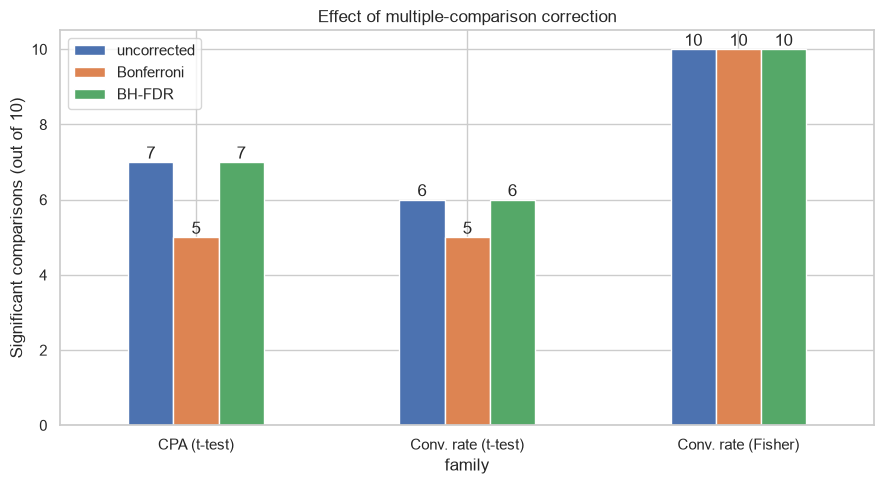

In [4]:
def pairs(rows):
    return [f"{a} vs {b}" for a, b in zip(rows.group_a, rows.group_b)] or "none"

for name, res in families.items():
    print(f"\n=== {name} ===")
    print("  Lost after Bonferroni:", pairs(res[res.significant & ~res.significant_bonferroni]))
    print("  Lost after BH:        ", pairs(res[res.significant & ~res.significant_fdr]))
    print("  Still significant after BH:", pairs(res[res.significant_fdr]))

# Grouped bar chart: uncorrected vs Bonferroni vs BH per family
ax = correction_summary[["uncorrected", "Bonferroni", "BH-FDR"]].plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_ylabel("Significant comparisons (out of 10)")
ax.set_title("Effect of multiple-comparison correction")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(OUT / "correction_comparison.png", dpi=120)
plt.show()

**✍️ Answer:**
1. **How many "significant" results disappeared?** Of the **23** results that were significant before correction, **Bonferroni removed 3** (CPA: def vs ghi and def vs jkl; daily conversion rate: ghi vs mno). **BH removed none.** We expected about 1.5 false positives from 30 tests, and most of our p-values are far below either line, so the main findings survive.
2. **Which correction fits a budget decision?** *Choose by the cost of a false winner.* Here a false winner means real money moved to a channel that isn't really better, which is exactly the risk the CMO named. So **Bonferroni** is the right line for the final decision to move money (the "goes live" case in §8). **BH** fits the exploration step (shortlisting which channels to test further). Step 8 asks for BH-corrected results, so the memo uses BH and flags where Bonferroni disagrees.
3. **What this means for moving budget:**
   - **Safe under both corrections:** `abc` is cheaper than every other channel (but tiny), and `def` is more expensive than `mno` and has the lowest conversion rate. Moving money **away from def** is well supported.
   - **Holds under BH only:** `def` is more expensive than `ghi` and `jkl`. Treat this as *likely*.
   - **Not supported:** any CPA ranking among `ghi`, `jkl` and `mno`. Don't move money between them on CPA grounds.

### Save the corrected results for notebooks 04 and 05

In [5]:
cpa_res.to_csv(OUT / "results_cpa_ttest.csv", index=False)
cvr_t_res.to_csv(OUT / "results_conv_rate_ttest.csv", index=False)
fisher_res.to_csv(OUT / "results_conv_rate_fisher.csv", index=False)
print("Saved (now with significant_bonferroni, p_value_fdr, significant_fdr)")

Saved (now with significant_bonferroni, p_value_fdr, significant_fdr)
